In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El fichero `pat20.rcp` del conjunto de instancias de Patterson (formato RCP: primera línea, número de actividades y de recursos; segunda, disponibilidad de cada recurso; después, una línea por actividad con su duración, sus necesidades de recursos, el número de sucesoras y sus sucesoras) describe un proyecto con actividades ficticias de inicio y fin de duración cero:

In [4]:
#| tbl-cap: "Contenido del fichero"
#| label: tbl-fichero
contenido_rcp = '''22      3
10      10      10
0       0       0       0       3       2       3       4
3       3       5       2       2       5       6
2       5       4       3       2       5       8
9       5       2       2       2       6       7
7       4       1       4       2       9       10
7       5       5       4       2       11      12
3       3       5       2       2       9       10
2       2       4       4       2       9       10
1       3       2       2       1       13
2       3       2       4       1       14
4       3       3       2       2       13      15
2       4       1       4       2       13      16
2       1       4       4       1       17
3       2       2       2       1       19
5       5       5       4       1       18
1       1       5       4       1       18
1       4       5       4       1       21
8       3       2       3       1       20
6       5       3       3       1       20
4       2       4       6       1       22
2       1       6       2       1       22
0       0       0       0       0
'''
print(contenido_rcp)

22      3
10      10      10
0       0       0       0       3       2       3       4
3       3       5       2       2       5       6
2       5       4       3       2       5       8
9       5       2       2       2       6       7
7       4       1       4       2       9       10
7       5       5       4       2       11      12
3       3       5       2       2       9       10
2       2       4       4       2       9       10
1       3       2       2       1       13
2       3       2       4       1       14
4       3       3       2       2       13      15
2       4       1       4       2       13      16
2       1       4       4       1       17
3       2       2       2       1       19
5       5       5       4       1       18
1       1       5       4       1       18
1       4       5       4       1       21
8       3       2       3       1       20
6       5       3       3       1       20
4       2       4       6       1       22
2       1       6       2  

In [5]:
pregunta_1 = "1. Lea el fichero con `read_rcp` (escribiéndolo antes en disco), construya el cuadro de prelaciones y el proyecto. ¿Cuántas actividades reales, ficticias, nodos y rutas tiene?  "
pregunta_2 = "2. Calcule τ = ‖R·t‖∞ y compárelo con la duración obtenida por el cálculo de tiempos (CPM). Indique las actividades críticas.  "
pregunta_3 = "3. Calcule la SVD de R y el cociente σ₁/σ₂. Ordene las actividades por |v₁| y mida la precisión del ranking: fracción de las k primeras (k = número de críticas) que son críticas.  "
pregunta_4 = "4. Compare el tamaño de R con el del grafo. ¿Cómo crece el número de rutas con el tamaño del proyecto y qué implica para proyectos de cientos de actividades?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Lea el fichero con `read_rcp` (escribiéndolo antes en disco), construya el cuadro de prelaciones y el proyecto. ¿Cuántas actividades reales, ficticias, nodos y rutas tiene?  

2. Calcule τ = ‖R·t‖∞ y compárelo con la duración obtenida por el cálculo de tiempos (CPM). Indique las actividades críticas.  

3. Calcule la SVD de R y el cociente σ₁/σ₂. Ordene las actividades por |v₁| y mida la precisión del ranking: fracción de las k primeras (k = número de críticas) que son críticas.  

4. Compare el tamaño de R con el del grafo. ¿Cómo crece el número de rutas con el tamaño del proyecto y qué implica para proyectos de cientos de actividades?  

# Resolución

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Lea el fichero con `read_rcp` (escribiéndolo antes en disco), construya el cuadro de prelaciones y el proyecto. ¿Cuántas actividades reales, ficticias, nodos y rutas tiene?  

In [7]:
from pmule import read_rcp
with open('pat20.rcp', 'w') as f:
    f.write(contenido_rcp)
datos_rcp = read_rcp('pat20.rcp')
datos_proyecto = pd.DataFrame({'predecessor': pd.Series({k: (v or '---') for k, v in datos_rcp['predecessors'].items()}),
                               'duration': datos_rcp['duration']['duration']})
datos_proyecto.index.name = 'activity'
datos_proyecto.T

activity,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,A11,A12,A13,A14,A15,A16,A17,A18,A19,A20,A21,A22
predecessor,---,A01,A01,A01,"A02,A03","A02,A04",A04,A03,"A05,A07,A08","A05,A07,A08",A06,A06,"A09,A11,A12",A10,A11,A12,A13,"A15,A16",A14,"A18,A19",A17,"A20,A21"
duration,0,3,2,9,7,7,3,2,1,2,4,2,2,3,5,1,1,8,6,4,2,0


In [8]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
t = datos_proyecto['duration'][R.columns]
Markdown(f'{len(proyecto)} actividades (incluidas las dos ficticias del formato, de duración 0), {len(proyecto.dummies)} ficticias añadidas por el grafo, {len(proyecto.nodes)} nodos y {R.shape[0]} rutas.')

22 actividades (incluidas las dos ficticias del formato, de duración 0), 6 ficticias añadidas por el grafo, 20 nodos y 16 rutas.

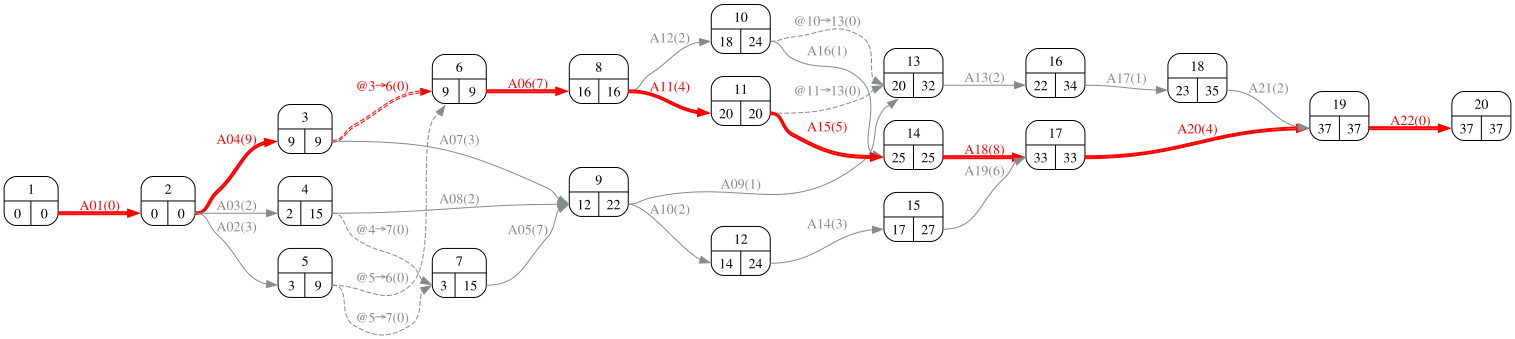

In [9]:
#| fig-cap: "Grafo PERT de la instancia"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=0.6, nodesep=0.3)

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule τ = ‖R·t‖∞ y compárelo con la duración obtenida por el cálculo de tiempos (CPM). Indique las actividades críticas.  

In [11]:
Rt = R @ t
tau = float(Rt.max())
cpm = proyecto.duration(datos_proyecto['duration'])
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
Markdown(f'τ = ‖R·t‖∞ = {tau:.0f}; CPM = {cpm}; coinciden: {tau == cpm}. Actividades críticas: {", ".join(criticas)}.')

τ = ‖R·t‖∞ = 37; CPM = 37; coinciden: True. Actividades críticas: A01, A04, A06, A11, A15, A18, A20, A22.

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Calcule la SVD de R y el cociente σ₁/σ₂. Ordene las actividades por |v₁| y mida la precisión del ranking: fracción de las k primeras (k = número de críticas) que son críticas.  

In [13]:
U, S, Vt = np.linalg.svd(R.values.astype(float), full_matrices=False)
v1 = np.abs(Vt[0, :])
ranking = pd.Series(v1, index=R.columns).sort_values(ascending=False)
k = len(criticas)
precision = len(set(ranking.index[:k]) & set(criticas)) / k
display(pd.DataFrame({'v₁': ranking.round(3), 'crítica': [a in criticas for a in ranking.index]}).T)
Markdown(f'σ₁/σ₂ = {S[0]/S[1]:.2f}. La mejor clasificada, {ranking.index[0]}, {"es" if ranking.index[0] in criticas else "no es"} crítica; precisión en las {k} primeras: {precision:.2f}.')

,A01,A22,A21,A17,A13,A06,A20,A02,A04,A09,A11,A12,A05,A18,A03,A19,A14,A10,A07,A15,A16,A08
v₁,0.485,0.485,0.267,0.267,0.267,0.255,0.219,0.187,0.185,0.127,0.127,0.127,0.117,0.115,0.113,0.104,0.104,0.104,0.058,0.058,0.058,0.056
crítica,True,True,False,False,False,True,True,False,True,False,True,False,False,True,False,False,False,False,False,True,False,False


σ₁/σ₂ = 1.76. La mejor clasificada, A01, es crítica; precisión en las 8 primeras: 0.50.

En el conjunto de Patterson (110 instancias) la actividad mejor clasificada por $v_1$ es crítica en el 77 % de los casos, y la identificación falla sobre todo cuando σ₁/σ₂ está cerca de 1 (dos direcciones dominantes). El ranking es informativo, no determinista.

## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Compare el tamaño de R con el del grafo. ¿Cómo crece el número de rutas con el tamaño del proyecto y qué implica para proyectos de cientos de actividades?  

In [15]:
Markdown(f'''El grafo tiene {len(proyecto.nodes)} nodos y {len(proyecto.activities)} arcos, pero R tiene {R.shape[0]} filas: el número de rutas crece de forma combinatoria con la anchura del grafo (en las instancias de 51 actividades de Patterson hay hasta varios miles). Por eso la fórmula es útil como herramienta analítica (sensibilidad, estructura, simulación vectorizada), mientras que para calcular τ en proyectos grandes basta el cálculo de tiempos hacia delante, que es lineal en el número de arcos.''')

El grafo tiene 20 nodos y 28 arcos, pero R tiene 16 filas: el número de rutas crece de forma combinatoria con la anchura del grafo (en las instancias de 51 actividades de Patterson hay hasta varios miles). Por eso la fórmula es útil como herramienta analítica (sensibilidad, estructura, simulación vectorizada), mientras que para calcular τ en proyectos grandes basta el cálculo de tiempos hacia delante, que es lineal en el número de arcos.